In [15]:
import warnings
warnings.filterwarnings('ignore')
import os
import scanpy as sc
import pandas as pd
import squidpy as sq
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
in_dir = "../../results/03_kidney_atlas/10_viz_cell2location"
out_dir = '../../results/03_kidney_atlas/11_run_nmf'

os.makedirs(out_dir, exist_ok=True)

In [5]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

In [37]:
df_list = []
for sample in sample_list:
    adata = sc.read_h5ad(f'{in_dir}/{sample}.h5ad')
    df = adata.obsm["q05_cell_abundance_w_sf"]
    df_list.append(df)

df = pd.concat(df_list, axis=0)

In [41]:
df

,q05cell_abundance_w_sf_ATL,q05cell_abundance_w_sf_CNT,q05cell_abundance_w_sf_DCT,q05cell_abundance_w_sf_DTL,q05cell_abundance_w_sf_EC,q05cell_abundance_w_sf_FIB,q05cell_abundance_w_sf_IC,q05cell_abundance_w_sf_IMM_B,q05cell_abundance_w_sf_IMM_MAC_M2,q05cell_abundance_w_sf_IMM_MAST,...,q05cell_abundance_w_sf_IMM_ncMON,q05cell_abundance_w_sf_IMM_pDC,q05cell_abundance_w_sf_NEU,q05cell_abundance_w_sf_PC,q05cell_abundance_w_sf_PEC,q05cell_abundance_w_sf_POD,q05cell_abundance_w_sf_PT,q05cell_abundance_w_sf_PapE,q05cell_abundance_w_sf_TAL,q05cell_abundance_w_sf_VSM_P
AACCAAGGTATCAGGC-1,0.081172,0.002647,0.005612,0.050907,0.092401,0.036346,0.005503,0.011269,0.009142,0.030502,...,0.017936,0.061221,0.007275,0.006062,0.055919,0.073718,0.180759,0.016061,0.035529,0.026270
AACCGCCAGACTACTT-1,0.011878,0.017708,0.002136,0.011089,0.017617,0.129772,0.000821,0.007985,0.007677,0.012765,...,0.009175,0.008545,0.004934,0.022156,0.002100,0.000057,0.397369,0.022130,0.225826,0.013265
AACGAATTGACCGGTT-1,0.006374,0.011317,0.004335,0.014047,0.106058,0.076710,0.063790,0.005404,0.039442,0.007816,...,0.002803,0.004825,0.003469,0.033592,0.002761,0.000055,0.538785,0.005000,0.032978,0.005179
AACTCAACCTTGACCA-1,0.003367,0.171877,0.006113,0.002523,0.082157,0.077058,0.326457,0.009026,0.053460,0.010339,...,0.009630,0.046081,0.014262,0.007208,0.003742,0.000187,0.068690,0.002655,0.001082,0.023421
AACTGCCTCGATAGGT-1,0.010154,0.043698,0.059834,0.017716,0.026416,0.214218,0.041645,0.010437,0.030335,0.022906,...,0.014012,0.009394,0.004990,0.056529,0.007313,0.000192,0.257736,0.014833,0.049568,0.013189
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TGTTCTGCTCTGTCGT-1,0.003658,0.000062,0.000083,0.020330,0.010696,0.085246,0.000005,0.005859,0.032289,0.001345,...,0.001913,0.000358,0.000932,0.000288,0.003613,0.000595,0.483476,0.000014,0.274239,0.000878
TGTTGGAACCTTCCGC-1,0.003145,0.005635,0.006197,0.068974,0.017733,0.136750,0.002144,0.001723,0.034028,0.009911,...,0.005501,0.008715,0.003125,0.000579,0.206808,0.000051,0.422042,0.012790,0.000179,0.005515
TGTTGGAACGAGGTCA-1,0.001193,0.011078,0.000318,0.016140,0.006959,0.288270,0.004606,0.003613,0.106316,0.004447,...,0.016671,0.006959,0.013397,0.001166,0.251875,0.026459,0.048262,0.002358,0.000052,0.031811
TGTTGGATGGACTTCT-1,0.000302,0.002076,0.007160,0.001482,0.029946,0.046143,0.049282,0.000576,0.022457,0.000601,...,0.000407,0.001078,0.001919,0.000081,0.003390,0.002573,0.795481,0.000435,0.000490,0.032371


In [39]:
# normalize rows to sum to 1
df = df.div(df.sum(axis=1), axis=0)

In [40]:
# run NMF
from sklearn.decomposition import NMF

model = NMF(n_components=10, init='random', random_state=0)
W = model.fit_transform(df)
H = model.components_
W_df = pd.DataFrame(W, index=df.index)
H_df = pd.DataFrame(H, columns=df.columns)

In [42]:
H_df = H_df.rename(index=lambda x: f'Factor_{x+1}')
H_df = H_df.transpose()

<Axes: >

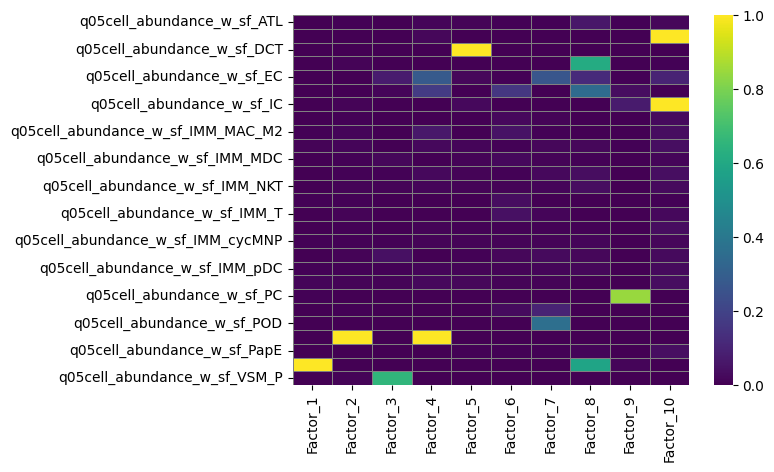

In [50]:
sns.heatmap(H_df, cmap='viridis', vmin=0, vmax=1, linewidths=0.5, linecolor='gray')